# 🦴 MediScan AI — Spine X-Ray Classification
### Model: EfficientNetB3 (Transfer Learning + Fine-Tuning)
### Classes: Normal | Scoliosis | Spondylolisthesis

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


In [2]:
# ── Config ────────────────────────────────────────────────────────────────────
BASE_DIR    = './spine_data_clean'
TRAIN_DIR   = os.path.join(BASE_DIR, 'train')
VAL_DIR     = os.path.join(BASE_DIR, 'val')
TEST_DIR    = os.path.join(BASE_DIR, 'test')

IMG_SIZE    = (224, 224)
BATCH_SIZE  = 16       # smaller batch = more stable training
NUM_CLASSES = 3

print('Config ready')

Config ready


In [3]:
# ── Data Generators with EfficientNet preprocessing ──────────────────────────
# Use preprocess_input from efficientnet — important!
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen  = ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True
)
val_generator = val_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)
test_generator = test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

with open('spine_class_indices.json', 'w') as f:
    json.dump(train_generator.class_indices, f)

print('Class indices:', train_generator.class_indices)
print(f'Train: {train_generator.samples} | Val: {val_generator.samples} | Test: {test_generator.samples}')

Found 1368 images belonging to 3 classes.
Found 293 images belonging to 3 classes.
Found 296 images belonging to 3 classes.
Class indices: {'Normal': 0, 'Scoliosis': 1, 'Spondylolisthesis': 2}
Train: 1368 | Val: 293 | Test: 296


In [4]:
# ── Class weights (fix imbalance) ─────────────────────────────────────────────
class_counts = {}
for cls, idx in train_generator.class_indices.items():
    path = os.path.join(TRAIN_DIR, cls)
    count = len([f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
    class_counts[cls] = count
    print(f'  {cls}: {count} images')

total = sum(class_counts.values())
class_weights = {
    idx: total / (NUM_CLASSES * class_counts[cls])
    for cls, idx in train_generator.class_indices.items()
}
print('\nClass weights:', {k: round(v, 3) for k, v in class_weights.items()})

  Normal: 248 images
  Scoliosis: 789 images
  Spondylolisthesis: 331 images

Class weights: {0: 1.839, 1: 0.578, 2: 1.378}


In [5]:
# ── Build EfficientNetB3 Model ────────────────────────────────────────────────
base_model = EfficientNetB3(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f'Base model layers: {len(base_model.layers)}')
print(f'Total params: {model.count_params():,}')

Base model layers: 385
Total params: 11,184,946


In [6]:
# ── Phase 1: Train top layers only ────────────────────────────────────────────
print('Phase 1: Training classifier head (base frozen)...')

history1 = model.fit(
    train_generator,
    epochs=15,
    validation_data=val_generator,
    class_weight=class_weights,
    callbacks=[
        ModelCheckpoint('spine_model.h5', monitor='val_accuracy', save_best_only=True, verbose=1),
        EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-7, verbose=1)
    ],
    verbose=1
)

print(f'Phase 1 best val accuracy: {max(history1.history["val_accuracy"]):.4f}')

Phase 1: Training classifier head (base frozen)...
Epoch 1/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 949ms/step - accuracy: 0.6654 - loss: 0.8326
Epoch 1: val_accuracy improved from None to 0.97270, saving model to spine_model.h5



Epoch 1: finished saving model to spine_model.h5
86/86 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - accuracy: 0.7851 - loss: 0.5026 - val_accuracy: 0.9727 - val_loss: 0.1528 - learning_rate: 0.0010
Epoch 2/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 846ms/step - accuracy: 0.8634 - loss: 0.3049
Epoch 2: val_accuracy improved from 0.97270 to 0.97952, saving model to spine_model.h5



Epoch 2: finished saving model to spine_model.h5
86/86 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.8896 - loss: 0.2708 - val_accuracy: 0.9795 - val_loss: 0.0890 - learning_rate: 0.0010
Epoch 3/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 901ms/step - accuracy: 0.9088 - loss: 0.2315
Epoch 3: val_accuracy improved from 0.97952 to 0.98294, saving model to spine_model.h5



Epoch 3: finished saving model to spine_model.h5
86/86 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.9174 - loss: 0.2128 - val_accuracy: 0.9829 - val_loss: 0.0477 - learning_rate: 0.0010
Epoch 4/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 864ms/step - accuracy: 0.8985 - loss: 0.2078
Epoch 4: val_accuracy improved from 0.98294 to 0.98976, saving model to spine_model.h5



Epoch 4: finished saving model to spine_model.h5
86/86 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.9123 - loss: 0.1940 - val_accuracy: 0.9898 - val_loss: 0.0312 - learning_rate: 0.0010
Epoch 5/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 775ms/step - accuracy: 0.9333 - loss: 0.1630
Epoch 5: val_accuracy did not improve from 0.98976
86/86 ━━━━━━━━━━━━━━━━━━━━ 80s 930ms/step - accuracy: 0.9335 - loss: 0.1656 - val_accuracy: 0.9898 - val_loss: 0.0434 - learning_rate: 0.0010
Epoch 6/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 813ms/step - accuracy: 0.9521 - loss: 0.1272
Epoch 6: val_accuracy improved from 0.98976 to 0.99317, saving model to spine_model.h5



Epoch 6: finished saving model to spine_model.h5
86/86 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.9437 - loss: 0.1446 - val_accuracy: 0.9932 - val_loss: 0.0254 - learning_rate: 0.0010
Epoch 7/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 760ms/step - accuracy: 0.9385 - loss: 0.1513
Epoch 7: val_accuracy did not improve from 0.99317
86/86 ━━━━━━━━━━━━━━━━━━━━ 80s 922ms/step - accuracy: 0.9349 - loss: 0.1533 - val_accuracy: 0.9898 - val_loss: 0.0273 - learning_rate: 0.0010
Epoch 8/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 775ms/step - accuracy: 0.9398 - loss: 0.1464
Epoch 8: val_accuracy improved from 0.99317 to 0.99659, saving model to spine_model.h5



Epoch 8: finished saving model to spine_model.h5
86/86 ━━━━━━━━━━━━━━━━━━━━ 81s 936ms/step - accuracy: 0.9357 - loss: 0.1651 - val_accuracy: 0.9966 - val_loss: 0.0185 - learning_rate: 0.0010
Epoch 9/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 758ms/step - accuracy: 0.9548 - loss: 0.1164
Epoch 9: val_accuracy did not improve from 0.99659
86/86 ━━━━━━━━━━━━━━━━━━━━ 79s 914ms/step - accuracy: 0.9518 - loss: 0.1105 - val_accuracy: 0.9966 - val_loss: 0.0178 - learning_rate: 0.0010
Epoch 10/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 782ms/step - accuracy: 0.9301 - loss: 0.1606
Epoch 10: val_accuracy did not improve from 0.99659
86/86 ━━━━━━━━━━━━━━━━━━━━ 81s 943ms/step - accuracy: 0.9386 - loss: 0.1477 - val_accuracy: 0.9932 - val_loss: 0.0195 - learning_rate: 0.0010
Epoch 11/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 784ms/step - accuracy: 0.9357 - loss: 0.1534
Epoch 11: val_accuracy did not improve from 0.99659
86/86 ━━━━━━━━━━━━━━━━━━━━ 81s 941ms/step - accuracy: 0.9423 - loss: 0.1436 - val_accuracy: 0.9898 - val_loss


Epoch 12: finished saving model to spine_model.h5

Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
86/86 ━━━━━━━━━━━━━━━━━━━━ 80s 925ms/step - accuracy: 0.9327 - loss: 0.1686 - val_accuracy: 1.0000 - val_loss: 0.0225 - learning_rate: 0.0010
Epoch 13/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 754ms/step - accuracy: 0.9572 - loss: 0.1455
Epoch 13: val_accuracy did not improve from 1.00000
86/86 ━━━━━━━━━━━━━━━━━━━━ 80s 926ms/step - accuracy: 0.9503 - loss: 0.1393 - val_accuracy: 1.0000 - val_loss: 0.0164 - learning_rate: 3.0000e-04
Epoch 14/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 799ms/step - accuracy: 0.9536 - loss: 0.1147
Epoch 14: val_accuracy did not improve from 1.00000
86/86 ━━━━━━━━━━━━━━━━━━━━ 84s 972ms/step - accuracy: 0.9547 - loss: 0.1121 - val_accuracy: 1.0000 - val_loss: 0.0146 - learning_rate: 3.0000e-04
Epoch 15/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 824ms/step - accuracy: 0.9466 - loss: 0.1111
Epoch 15: val_accuracy did not improve from 1.00000
86/86 ━━━━━━━━━━━━━━

In [7]:
# ── Phase 2: Fine-tune top layers of EfficientNetB3 ──────────────────────────
print('Phase 2: Fine-tuning top layers of EfficientNetB3...')

base_model.trainable = True

# Freeze all but last 40 layers
for layer in base_model.layers[:-40]:
    layer.trainable = False

# Very low learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model.fit(
    train_generator,
    epochs=25,
    validation_data=val_generator,
    class_weight=class_weights,
    callbacks=[
        ModelCheckpoint('spine_model.h5', monitor='val_accuracy', save_best_only=True, verbose=1),
        EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-8, verbose=1)
    ],
    verbose=1
)

print(f'Phase 2 best val accuracy: {max(history2.history["val_accuracy"]):.4f}')
print('Best model saved as spine_model.h5')

Phase 2: Fine-tuning top layers of EfficientNetB3...
Epoch 1/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8818 - loss: 0.3465
Epoch 1: val_accuracy improved from None to 0.98976, saving model to spine_model.h5



Epoch 1: finished saving model to spine_model.h5
86/86 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.8823 - loss: 0.3262 - val_accuracy: 0.9898 - val_loss: 0.0344 - learning_rate: 1.0000e-05
Epoch 2/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 972ms/step - accuracy: 0.8937 - loss: 0.2564
Epoch 2: val_accuracy did not improve from 0.98976
86/86 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.8969 - loss: 0.2713 - val_accuracy: 0.9795 - val_loss: 0.0590 - learning_rate: 1.0000e-05
Epoch 3/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 967ms/step - accuracy: 0.9238 - loss: 0.2139
Epoch 3: val_accuracy did not improve from 0.98976
86/86 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.9174 - loss: 0.2222 - val_accuracy: 0.9795 - val_loss: 0.0714 - learning_rate: 1.0000e-05
Epoch 4/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9173 - loss: 0.2155
Epoch 4: val_accuracy did not improve from 0.98976

Epoch 4: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
86/86 ━━━━━━━━━━━━━━━━━━━━ 104s 1s

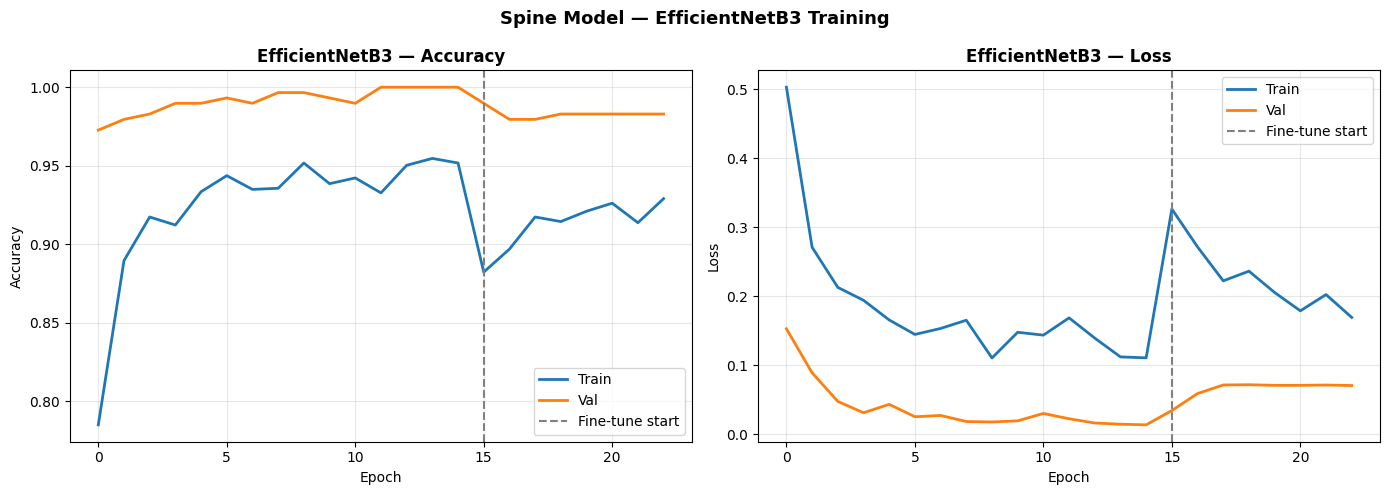

Saved: spine_training_curves.png


In [8]:
# ── Training Curves ───────────────────────────────────────────────────────────
acc   = history1.history['accuracy']     + history2.history['accuracy']
val   = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss  = history1.history['loss']         + history2.history['loss']
vloss = history1.history['val_loss']     + history2.history['val_loss']
p1    = len(history1.history['accuracy'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, train, val_, title, ylabel in [
    (axes[0], acc, val, 'Accuracy', 'Accuracy'),
    (axes[1], loss, vloss, 'Loss', 'Loss')
]:
    ax.plot(train, label='Train', linewidth=2)
    ax.plot(val_,  label='Val',   linewidth=2)
    ax.axvline(x=p1, color='gray', linestyle='--', label='Fine-tune start')
    ax.set_title(f'EfficientNetB3 — {title}', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel)
    ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle('Spine Model — EfficientNetB3 Training', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('spine_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: spine_training_curves.png')

In [9]:
# ── Evaluate on Test Set ──────────────────────────────────────────────────────
from tensorflow.keras.models import load_model
model = load_model('spine_model.h5')

test_loss, test_acc = model.evaluate(test_generator, verbose=1)
print(f'\n Test Accuracy : {test_acc*100:.2f}%')
print(f'Test Loss     : {test_loss:.4f}')

19/19 ━━━━━━━━━━━━━━━━━━━━ 30s 798ms/step - accuracy: 0.9561 - loss: 0.1413

 Test Accuracy : 95.61%
Test Loss     : 0.1413


In [10]:
# ── Classification Report ─────────────────────────────────────────────────────
test_generator.reset()
preds = model.predict(test_generator, verbose=1)
pred_classes = np.argmax(preds, axis=1)
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

print('\nClassification Report:')
print(classification_report(true_classes, pred_classes, target_names=class_labels))

19/19 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step 

Classification Report:
                   precision    recall  f1-score   support

           Normal       1.00      0.80      0.89        54
        Scoliosis       0.93      1.00      0.96       170
Spondylolisthesis       1.00      0.97      0.99        72

         accuracy                           0.96       296
        macro avg       0.98      0.92      0.95       296
     weighted avg       0.96      0.96      0.95       296



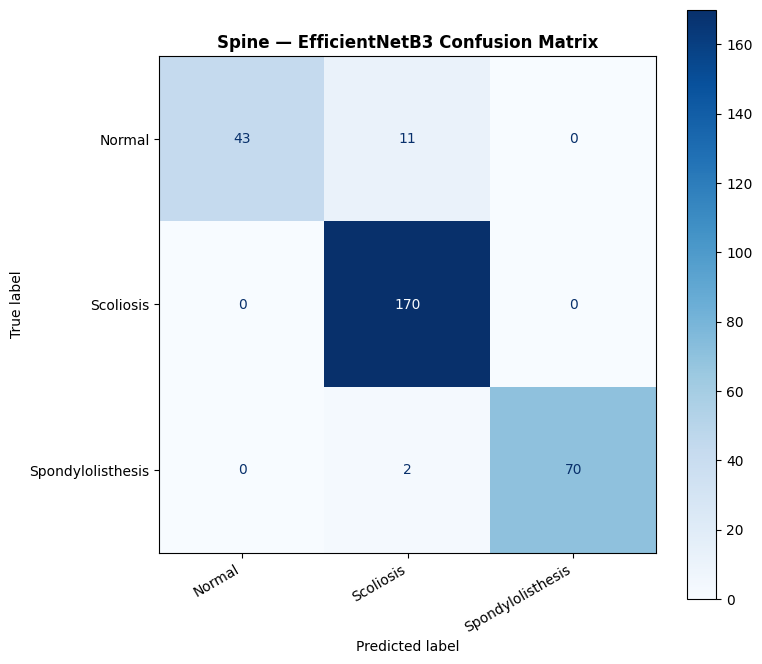

Saved: spine_confusion_matrix.png


In [11]:
# ── Confusion Matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(true_classes, pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(ax=ax, cmap='Blues')
ax.set_title('Spine — EfficientNetB3 Confusion Matrix', fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('spine_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: spine_confusion_matrix.png')

In [12]:
# ── Summary ───────────────────────────────────────────────────────────────────
print('  MediScan AI — Spine Model Summary')
print(f'  Architecture  : EfficientNetB3 (Transfer Learning)')
print(f'  Pretrained on : ImageNet (1.2M images)')
print(f'  Fine-tuned    : Top 40 layers')
print(f'  Classes       : Normal, Scoliosis, Spondylolisthesis')
print(f'  Input size    : 224 x 224 x 3')
print(f'  Test accuracy : {test_acc*100:.2f}%')
print(f'  Model saved   : spine_model.h5')
print('=' * 55)

  MediScan AI — Spine Model Summary
  Architecture  : EfficientNetB3 (Transfer Learning)
  Pretrained on : ImageNet (1.2M images)
  Fine-tuned    : Top 40 layers
  Classes       : Normal, Scoliosis, Spondylolisthesis
  Input size    : 224 x 224 x 3
  Test accuracy : 95.61%
  Model saved   : spine_model.h5
